In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv('netflix_cleaned.csv')

print("Dataset loaded!")
print("Shape:", df.shape)
df.head()

Dataset loaded!
Shape: (8790, 15)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,duration_num,duration_type,type_encoded
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,90.0,min,0
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,1.0,Season,1
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,1.0,Season,1
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,91.0,min,0
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,125.0,min,0


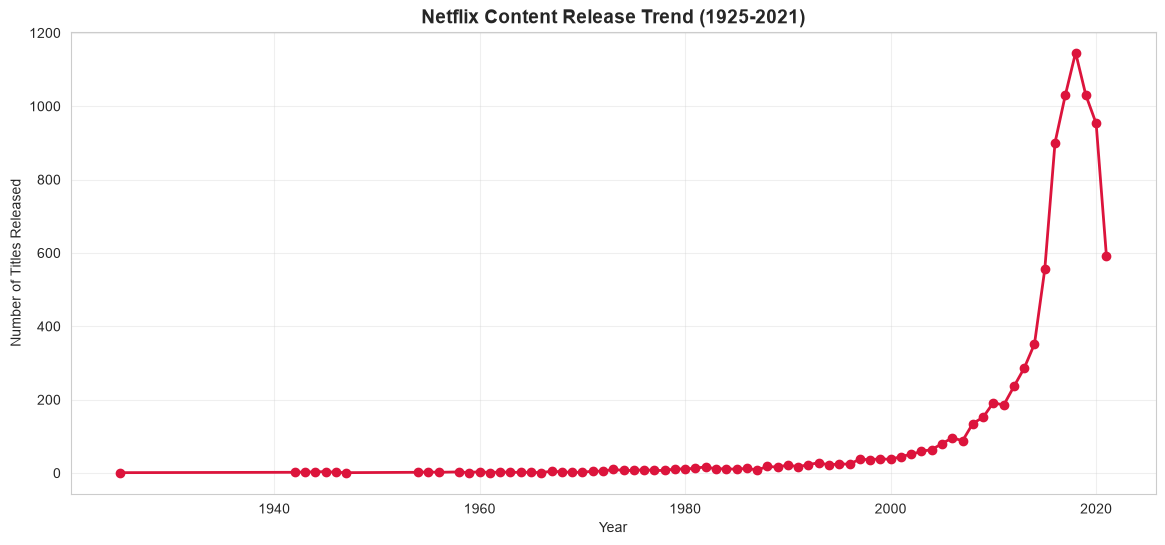

In [3]:
yearly_content = df['release_year'].value_counts().sort_index()

plt.figure(figsize=(14, 6))
plt.plot(yearly_content.index, yearly_content.values, marker='o', color='crimson', linewidth=2)
plt.title('Netflix Content Release Trend (1925-2021)', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Number of Titles Released')
plt.grid(True, alpha=0.3)
plt.show()

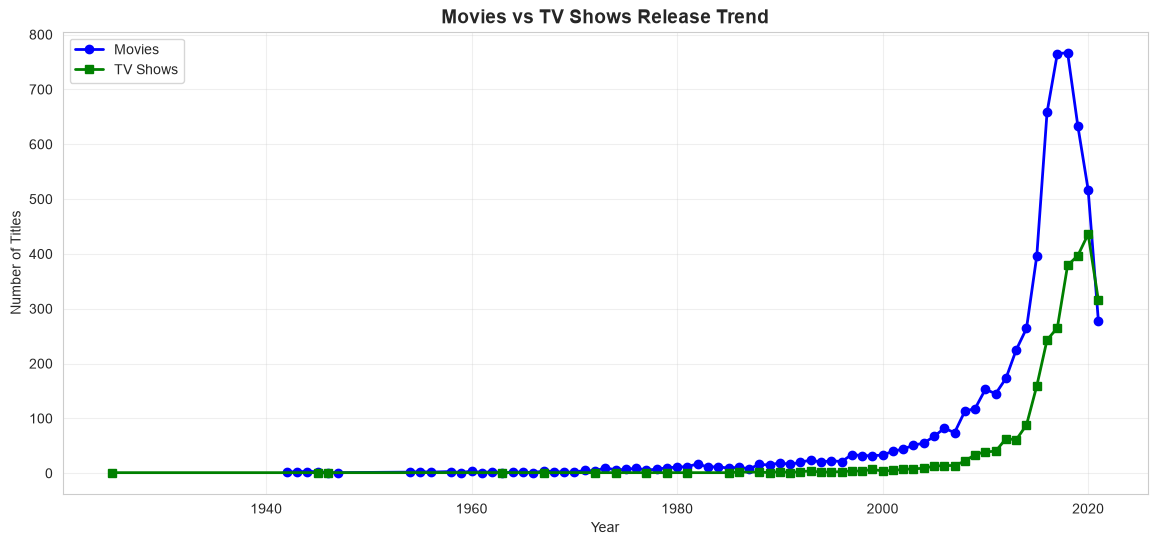

In [4]:
movies_yearly = df[df['type']=='Movie']['release_year'].value_counts().sort_index()
tv_yearly = df[df['type']=='TV Show']['release_year'].value_counts().sort_index()

plt.figure(figsize=(14, 6))
plt.plot(movies_yearly.index, movies_yearly.values, marker='o', label='Movies', color='blue', linewidth=2)
plt.plot(tv_yearly.index, tv_yearly.values, marker='s', label='TV Shows', color='green', linewidth=2)
plt.title('Movies vs TV Shows Release Trend', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
recent_data = df[df['release_year'] >= 2000]

print("Recent years ka data:")
print("Total titles (2000-2021):", len(recent_data))

yearly_recent = recent_data['release_year'].value_counts().sort_index()
print("\nYear-wise counts (last 10 years):")
print(yearly_recent.tail(10))

Recent years ka data:
Total titles (2000-2021): 8265

Year-wise counts (last 10 years):
release_year
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, dtype: int64


In [6]:
from sklearn.linear_model import LinearRegression

forecast_data = df[(df['release_year'] >= 2010) & (df['release_year'] <= 2021)]

yearly_counts = forecast_data['release_year'].value_counts().sort_index()

X = yearly_counts.index.values.reshape(-1, 1)
y = yearly_counts.values

model = LinearRegression()
model.fit(X, y)

print("Model trained!")
print(f"Coefficient (Slope): {model.coef_[0]:.2f}")
print(f"Intercept: {model.intercept_:.2f}")

Model trained!
Coefficient (Slope): 82.34
Intercept: -165340.13


In [7]:
future_years = np.array([2022, 2023, 2024, 2025, 2026]).reshape(-1, 1)
predictions = model.predict(future_years)

print("Future Content Predictions:")
print("="*40)
for year, pred in zip(future_years.flatten(), predictions):
    print(f"{year}: {int(pred)} titles (approx)")

Future Content Predictions:
2022: 1156 titles (approx)
2023: 1239 titles (approx)
2024: 1321 titles (approx)
2025: 1403 titles (approx)
2026: 1486 titles (approx)


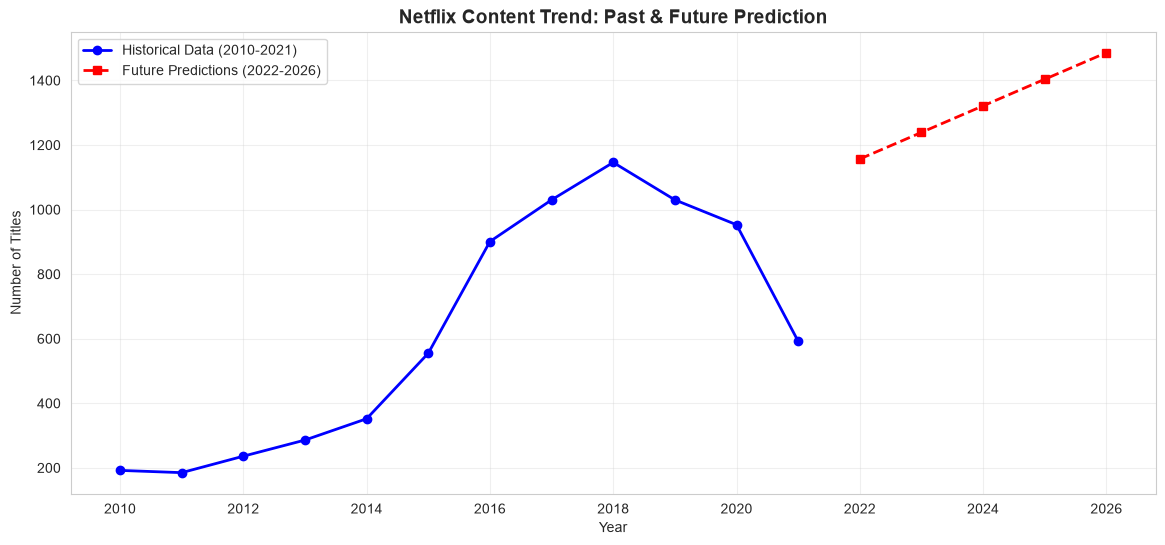

In [8]:
plt.figure(figsize=(14, 6))

plt.plot(X.flatten(), y, marker='o', label='Historical Data (2010-2021)', 
         color='blue', linewidth=2)

plt.plot(future_years.flatten(), predictions, marker='s', 
         label='Future Predictions (2022-2026)', color='red', 
         linewidth=2, linestyle='--')

plt.title('Netflix Content Trend: Past & Future Prediction', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [9]:
print("="*60)
print("📊 TREND PREDICTION INSIGHTS")
print("="*60)
print(f"\n1. Earliest Release Year: {df['release_year'].min()}")
print(f"2. Latest Release Year: {df['release_year'].max()}")
print(f"3. Peak Year: {yearly_content.idxmax()} ({yearly_content.max()} titles)")
print(f"4. Total Titles (2010-2021): {len(forecast_data)}")
print(f"5. Trend: Content growth {'increasing' if model.coef_[0] > 0 else 'decreasing'}")
print(f"6. Predicted 2025: ~{int(predictions[3])} titles")

📊 TREND PREDICTION INSIGHTS

1. Earliest Release Year: 1925
2. Latest Release Year: 2021
3. Peak Year: 2018 (1146 titles)
4. Total Titles (2010-2021): 7458
5. Trend: Content growth increasing
6. Predicted 2025: ~1403 titles
